In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVR

In [2]:
df=pd.read_csv("gym_crowdedness.csv")

In [3]:
df.head()

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


In [4]:
df.shape

(62184, 11)

In [5]:
df.columns

Index(['number_people', 'date', 'timestamp', 'day_of_week', 'is_weekend',
       'is_holiday', 'temperature', 'is_start_of_semester',
       'is_during_semester', 'month', 'hour'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   number_people         62184 non-null  int64  
 1   date                  62184 non-null  str    
 2   timestamp             62184 non-null  int64  
 3   day_of_week           62184 non-null  int64  
 4   is_weekend            62184 non-null  int64  
 5   is_holiday            62184 non-null  int64  
 6   temperature           62184 non-null  float64
 7   is_start_of_semester  62184 non-null  int64  
 8   is_during_semester    62184 non-null  int64  
 9   month                 62184 non-null  int64  
 10  hour                  62184 non-null  int64  
dtypes: float64(1), int64(9), str(1)
memory usage: 5.2 MB


In [7]:
df.describe()

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
count,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000
mean,29.072543,45799.437958,2.982504,0.282870,0.002573,58.557108,0.078831,0.660218,7.439824,12.236460
std,22.689026,24211.275891,1.996825,0.450398,0.050660,6.316396,0.269476,0.473639,3.445069,6.717631
min,0.000000,0.000000,0.000000,0.000000,0.000000,38.140000,0.000000,0.000000,1.000000,0.000000
25%,9.000000,26624.000000,1.000000,0.000000,0.000000,55.000000,0.000000,0.000000,5.000000,7.000000
50%,28.000000,46522.500000,3.000000,0.000000,0.000000,58.340000,0.000000,1.000000,8.000000,12.000000
75%,43.000000,66612.000000,5.000000,1.000000,0.000000,62.280000,0.000000,1.000000,10.000000,18.000000
max,145.000000,86399.000000,6.000000,1.000000,1.000000,87.170000,1.000000,1.000000,12.000000,23.000000


In [8]:
df["date"]=pd.to_datetime(df["date"],utc=True)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   number_people         62184 non-null  int64              
 1   date                  62184 non-null  datetime64[us, UTC]
 2   timestamp             62184 non-null  int64              
 3   day_of_week           62184 non-null  int64              
 4   is_weekend            62184 non-null  int64              
 5   is_holiday            62184 non-null  int64              
 6   temperature           62184 non-null  float64            
 7   is_start_of_semester  62184 non-null  int64              
 8   is_during_semester    62184 non-null  int64              
 9   month                 62184 non-null  int64              
 10  hour                  62184 non-null  int64              
dtypes: datetime64[us, UTC](1), float64(1), int64(9)
memory usage: 5.2 MB


In [16]:
df["year"]=df["date"].dt.year

In [17]:
df.drop("date",axis=1,inplace=True)

In [18]:
df.head()

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,61211,4,0,0,71.76,0,0,8,17,2015
1,45,62414,4,0,0,71.76,0,0,8,17,2015
2,40,63015,4,0,0,71.76,0,0,8,17,2015
3,44,63616,4,0,0,71.76,0,0,8,17,2015
4,45,64217,4,0,0,71.76,0,0,8,17,2015


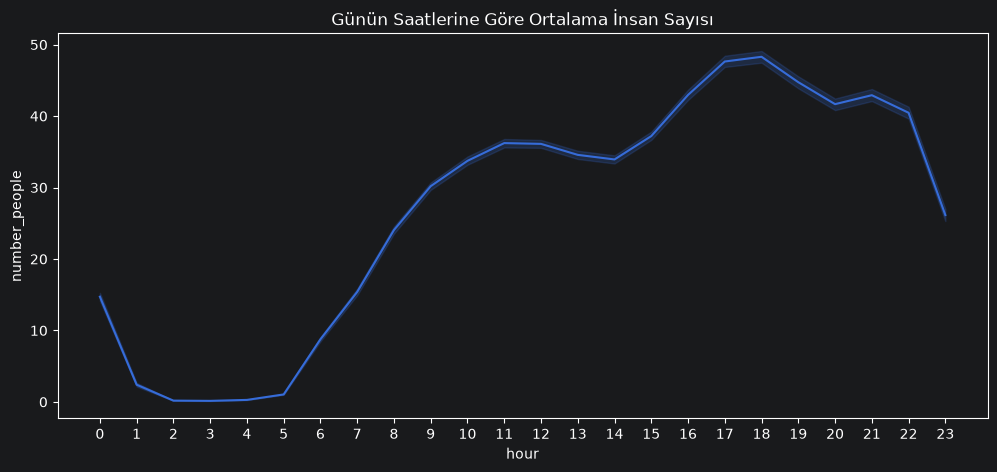

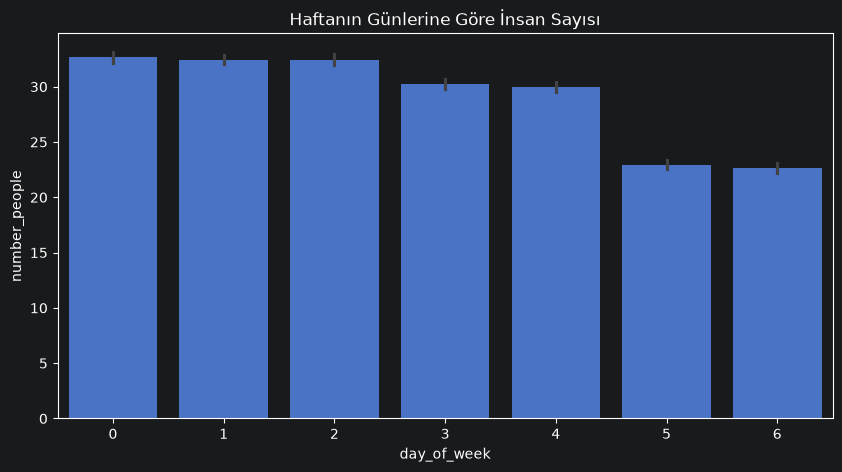

In [19]:
# Günün saatlerine göre insan sayısı
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x='hour', y='number_people', estimator='mean')
plt.title('Günün Saatlerine Göre Ortalama İnsan Sayısı')
plt.xticks(range(0, 24))
plt.show()

# Haftanın günlerine göre (0: Pazartesi, 6: Pazar)
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='day_of_week', y='number_people')
plt.title('Haftanın Günlerine Göre İnsan Sayısı')
plt.show()

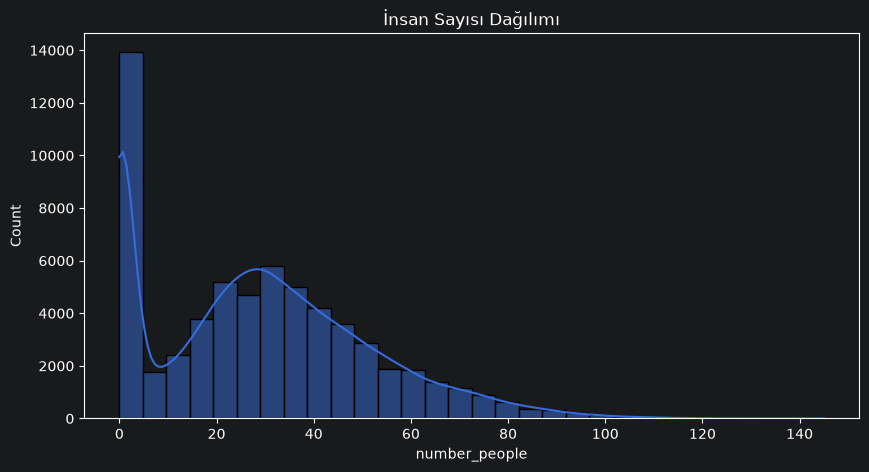

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# İnsan sayısının dağılımı
plt.figure(figsize=(10, 5))
sns.histplot(df['number_people'], kde=True, bins=30)
plt.title('İnsan Sayısı Dağılımı')
plt.show()

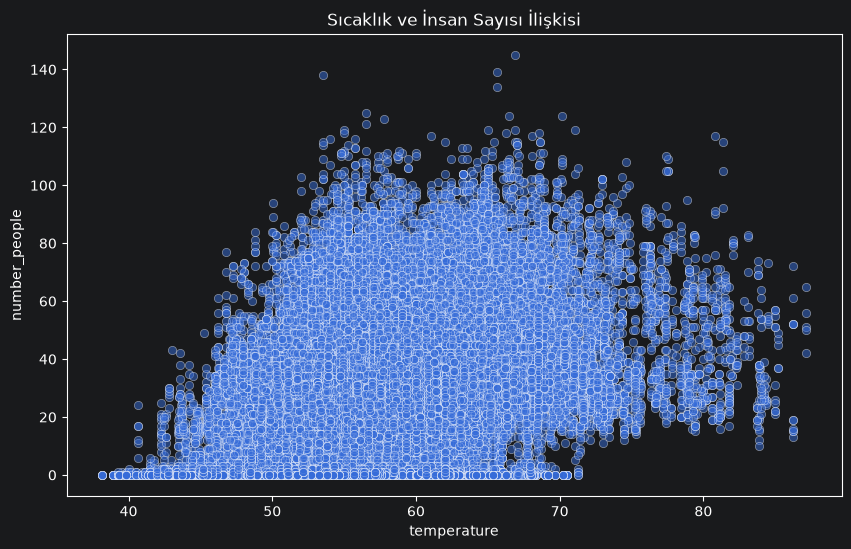

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='temperature', y='number_people', alpha=0.5)
plt.title('Sıcaklık ve İnsan Sayısı İlişkisi')
plt.show()

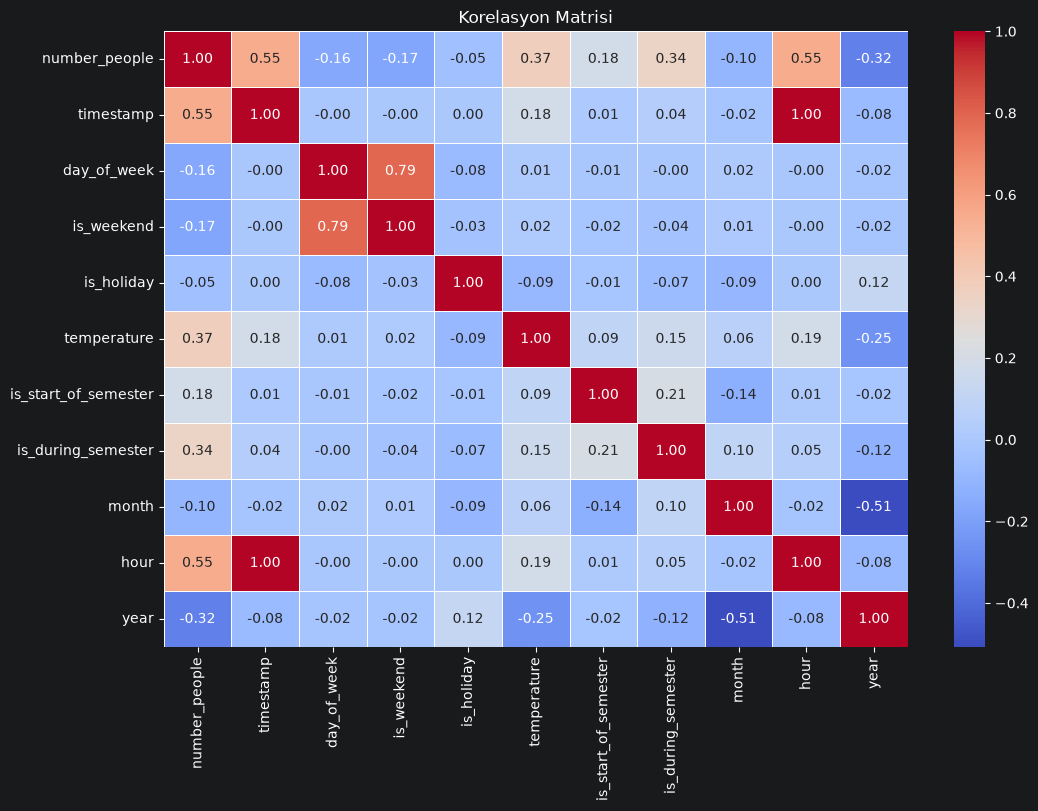

In [22]:
plt.figure(figsize=(12, 8))
# Sadece sayısal kolonları seçip korelasyon matrisi oluşturuyoruz
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Korelasyon Matrisi')
plt.show()

In [23]:
X=df.drop("number_people",axis=1)
y=df["number_people"]
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error


In [26]:
def calculate_model_metrics(true,predicted):
    mae=mean_absolute_error(true,predicted)
    mse=mean_squared_error(true,predicted)
    r2=r2_score(true,predicted)
    rmse=np.sqrt(mean_squared_error(true,predicted))
    return mae,r2,rmse

In [28]:
models={
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Decision Tree Regression": DecisionTreeRegressor(),
    "Random Forest Regression": RandomForestRegressor(),
    "KNN Regression": KNeighborsRegressor()

}

In [30]:
for i in range(len(models)):
    model=list(models.values())[i]
    model.fit(X_train,y_train)

    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)
    mae,r2,rmse=calculate_model_metrics(y_train,y_train_pred)

    model_train_mae,model_train_r2,model_train_rmse =calculate_model_metrics(y_train,y_train_pred)
    model_test_mae,model_test_r2,model_test_rmse =calculate_model_metrics(y_test,y_test_pred)

    print("---------------------------")
    print("train")

    print(list(models.values())[i])
    print("rmse: ",model_train_rmse)
    print("mae: ",model_train_mae)
    print("r2: ",model_train_r2)

    print("---------------------------")
    print("test")
    print(list(models.values())[i])
    print("rmse: ",model_test_rmse)
    print("mae: ",model_test_mae)
    print("r2: ",model_test_r2)

    print("---------------------------")
    print("---------------------------")



---------------------------
train
LinearRegression()
rmse:  14.372222584088185
mae:  10.762648201399404
r2:  0.5983396414918644
---------------------------
test
LinearRegression()
rmse:  14.26743086799721
mae:  10.657060870233183
r2:  0.6061517081687222
---------------------------
---------------------------
---------------------------
train
Ridge()
rmse:  14.372226856530505
mae:  10.76250297289584
r2:  0.5983394026880247
---------------------------
test
Ridge()
rmse:  14.267496360649329
mae:  10.656985524012212
r2:  0.606148092349083
---------------------------
---------------------------
---------------------------
train
Lasso()
rmse:  14.620821648179279
mae:  10.963161592465873
r2:  0.5843242765766509
---------------------------
test
Lasso()
rmse:  14.530304616898539
mae:  10.882610586122896
r2:  0.5915049008122222
---------------------------
---------------------------
---------------------------
train
DecisionTreeRegressor()
rmse:  0.21060492262331346
mae:  0.005045530383741733
r2